# 6.2 PCA

In [1]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

iris= load_iris()
#넘파이 데이터 세트를 판다스 DataFrame으로 변환
columns= ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
irisDF= pd.DataFrame(iris.data, columns= columns)
irisDF['target']= iris.target
irisDF.head(3)

,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


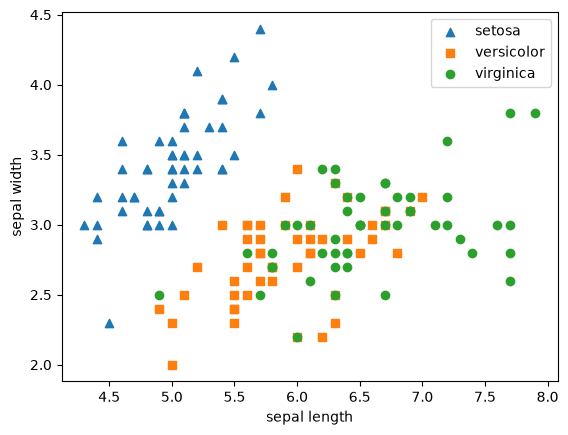

In [2]:
#setosa는 세모, virsicolor는 네모, virgicana는 동그라미로 표현 
markers= ['^', 's', 'o']

#setosa의 target값은 0, versicolor는 1, virgicana는 2. 각 target 별로 다른 모양으로 산점도로 표시
for i , marker in enumerate(markers):
    x_axis_data= irisDF[irisDF['target']==i]['sepal_length']
    y_axis_data= irisDF[irisDF['target']==i]['sepal_width']
    plt.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])


plt.legend()
plt.xlabel('sepal length')
plt.ylabel('sepal width')
plt.show()



In [3]:
from sklearn.preprocessing import StandardScaler

#Target 값을 제외한 모든 속성 값을 StandardScaler를 이용해 표준 정규 분포를 가지는 값들로 변환 
iris_scaled= StandardScaler().fit_transform(irisDF.iloc[:, :-1])

In [4]:
from sklearn.decomposition import PCA
pca= PCA(n_components=2)

#fit, transform을 호출해 PCA 변환 데이터 반환
pca.fit(iris_scaled)
iris_pca= pca.transform(iris_scaled)
print(iris_pca.shape)

(150, 2)


In [5]:
#PCA 변환된 데이터의 칼럼명륵 각각 pca_conponent_1, pca_conponent_2로 명명
pca_columns= ['pca_conponent_1', 'pca_conponent_2']
irisDF_pca= pd.DataFrame(iris_pca, columns=pca_columns)
irisDF_pca['target']= iris.target
irisDF_pca.head(3)

,pca_conponent_1,pca_conponent_2,target
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0


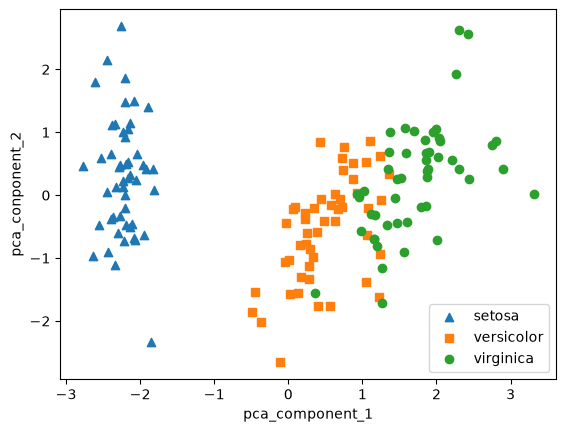

In [6]:
#setosa는 세모, virsicolor는 네모, virgicana는 동그라미로 표현 
markers= ['^', 's', 'o']

#pca_conponent_1을 x축, pca_conponent_2을 y축으로 scatter plot 수행 
for i , marker in enumerate(markers):
    x_axis_data= irisDF_pca[irisDF_pca['target']==i]['pca_conponent_1']
    y_axis_data= irisDF_pca[irisDF_pca['target']==i]['pca_conponent_2']
    plt.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])


plt.legend()
plt.xlabel('pca_component_1') 
plt.ylabel('pca_conponent_2')
plt.show()

#변환 전보다 비교적 versicolor, virgicana 구분이 가능. 
# -> pca의 첫번째 새로운 축인 pca_component_1이 원본 데이터의 변동성을 잘 반영했기 때문. 

In [7]:
print(pca.explained_variance_ratio_)

[0.72962445 0.22850762]


원본 붓꽃 데이터세트와 PCA로 변환된 데이터 세트에 각각 분류 적용하여 결과비교 

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

rcf = RandomForestClassifier(random_state=156)
scores= cross_val_score(rcf, iris.data, iris.target, scoring='accuracy', cv=3)
print('원본 데이터 교차 검증 개별 정확도:', scores)
print('원본 데이터 교차 검증 개별 정확도:', np.mean(scores))

원본 데이터 교차 검증 개별 정확도: [0.98 0.94 0.96]
원본 데이터 교차 검증 개별 정확도: 0.96


In [9]:
pca_X = irisDF_pca.iloc[:, :2]
scores_pca = cross_val_score(rcf, pca_X, iris.target, scoring='accuracy', cv=3)
print('PCA 변환 데이터 교차 검증 개별 정확도:', scores_pca)
print('PCA 변환 데이터 평균 정확도:', np.mean(scores_pca))

#변환 후에는 성능이 떨어질 수 밖에 없다. 속성 개수가 절반으로 줄어든 것을 고려한다면, 원본 데이터의 특성을 상당 부분 유지한다고 볼 수 있다. 

PCA 변환 데이터 교차 검증 개별 정확도: [0.88 0.88 0.88]
PCA 변환 데이터 평균 정확도: 0.88


In [12]:
%pip install --upgrade xlrd

  Using cached xlrd-2.0.2-py2.py3-none-any.whl.metadata (3.5 kB)
Using cached xlrd-2.0.2-py2.py3-none-any.whl (96 kB)
Note: you may need to restart the kernel to use updated packages.


In [13]:
#header로 의미 없는 첫 행 제거, iloc으로 기존 id 제거 
import pandas as pd

df= pd.read_excel('pca_credit_card.xls', header=1, sheet_name='Data').iloc[0:, 1:]
print(df.shape)
df.head(3)

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [14]:
# 'default payment next month 속성이 Target값. -> 연체일 경우 1, 정상납부 0 
df.rename(columns= {'PAY_0':'PAY_1', 'default payment next month':'default'}, inplace=True)
y_target=df['default']
X_features= df.drop('default', axis=1)

<Axes: >

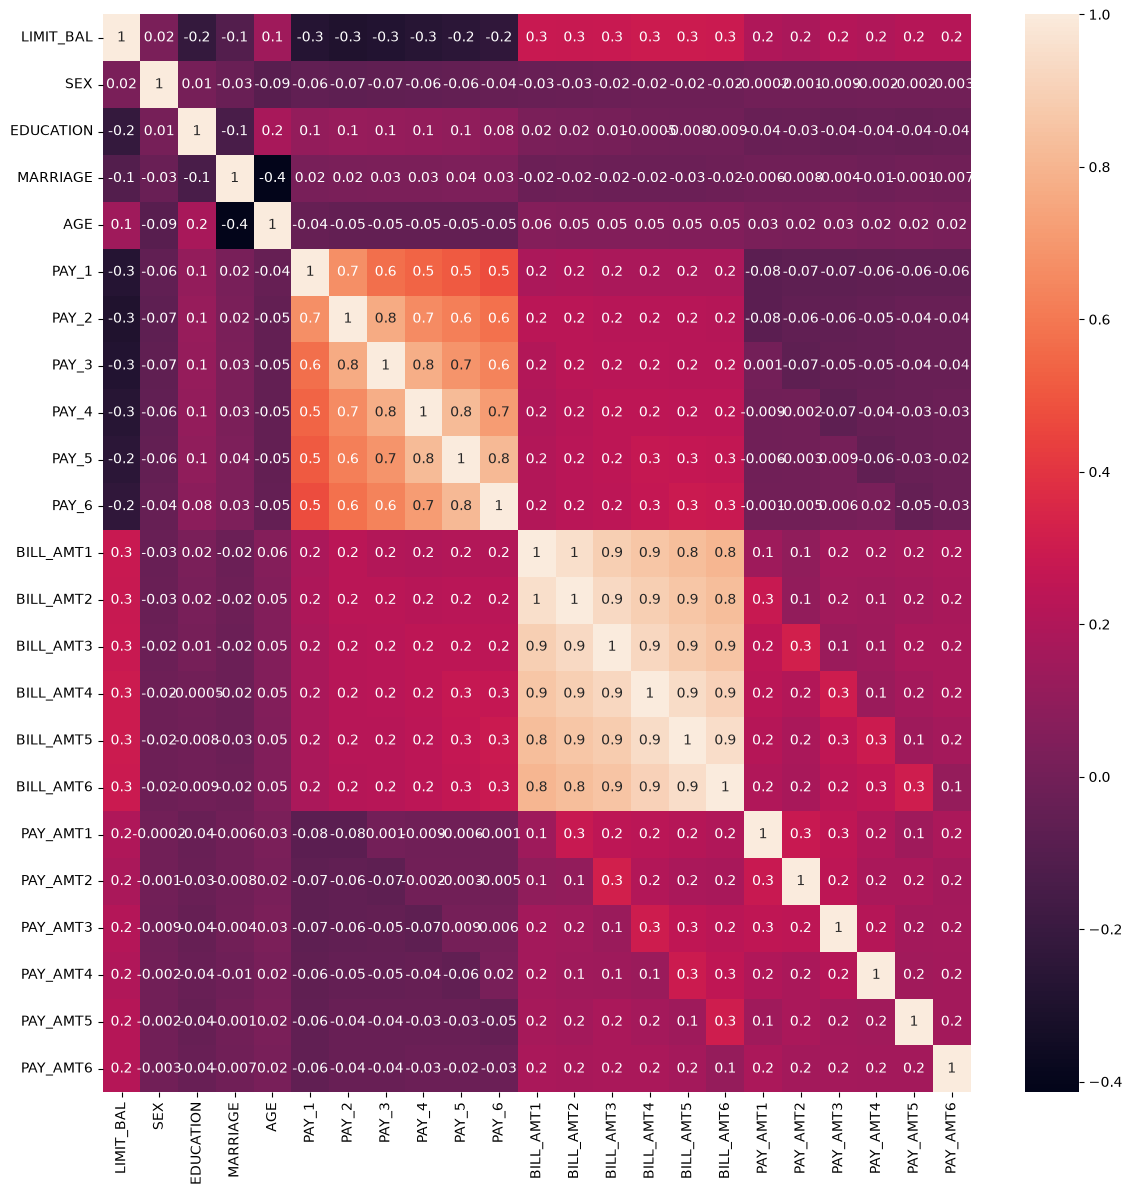

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

corr= X_features.corr()
plt.figure(figsize= (14, 14))
sns.heatmap(corr, annot=True, fmt= '.1g')

In [17]:
#높은 상관도를 가진 속성들은 소수의 PCA 만으로도 자연스럽게 이 속성들의 변동을 수용할 수 있다. 
#높은 상관도를 가진 6개 속성을 2개로 PCA 변환 

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

#BILL_AMT1 ~ BILL_AMT6 까지 6개의 속성명 생성 
cols_bill= ['BILL_AMT'+str(i) for i in range(1,7)]
print('대상 속성명:', cols_bill)

#2개의 PCA 속성을 가진 PCA 객체 생성하고, explained_variance_ratio_ 계산을 위해 fit() 호출 
scaler= StandardScaler()
df_cols_scaled= scaler.fit_transform(X_features[cols_bill])
pca= PCA(n_components=2)
pca.fit(df_cols_scaled)
print('PCA Component별 변동성:', pca.explained_variance_ratio_)

대상 속성명: ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
PCA Component별 변동성: [0.90555253 0.0509867 ]


원본 데이터세트와 PCA로 변환된 데이터 세트에 각각 분류 적용하여 결과비교 

In [18]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rcf= RandomForestClassifier(n_estimators=300, random_state=156)
scores= cross_val_score(rcf, X_features, y_target, scoring='accuracy', cv=3)

print('CV=3 인 경우의 개별 Fold세트별 정확도:', scores)
print('평균 정확도:{0:.4f}'.format(np.mean(scores)))

CV=3 인 경우의 개별 Fold세트별 정확도: [0.8083 0.8196 0.8232]
평균 정확도:0.8170


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

#원본 데이터 세트에 먼저 StandardScaler 적용 
scaler= StandardScaler()
df_scaled= scaler.fit_transform(X_features)

#6개의 컴포넌트를 가진 PCA 변환을 수행하고 cross_val_score()로 분류 예측 수행 
pca= PCA(n_components=6)
df_pca= pca.fit_transform(df_scaled)
scores_pca= cross_val_score(rcf, df_pca, y_target, scoring='accuracy', cv=3)

print('CV=3 인 경우의 PCA 변환된 개별 Fold세트별 정확도:', scores_pca)
print('PCA 변환 데이터 세트 평균 정확도:{0:.4f}'.format(np.mean(scores_pca)))

#23개 -> 6개 속성으로 변환했지만, 1~2%의 예측 성능 저하만 발생함. 


CV=3 인 경우의 PCA 변환된 개별 Fold세트별 정확도: [0.7913 0.7972 0.802 ]
PCA 변환 데이터 세트 평균 정확도:0.7968


# 6.3 LDA

붓꽃 데이터 세트를 LDA 를 이용해 변환, 그 결과를 품종별로 시각화하기

In [21]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris

iris= load_iris()
iris_scaled= StandardScaler().fit_transform(iris.data)

In [23]:
lda= LinearDiscriminantAnalysis(n_components=2)
lda.fit(iris_scaled, iris.target)
iris_lda= lda.transform(iris_scaled)
print(iris_lda.shape)

(150, 2)


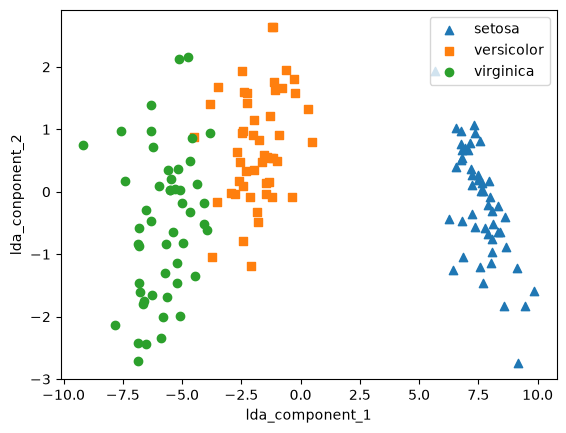

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

lda_columns= ['lda_component_1', 'lda_component_2']
irisDF_lda= pd.DataFrame(iris_lda, columns=lda_columns)
irisDF_lda['target']= iris.target

#setosa는 세모, virsicolor는 네모, virgicana는 동그라미로 표현 
markers= ['^', 's', 'o']

#pca_conponent_1을 x축, pca_conponent_2을 y축으로 scatter plot 수행 
for i , marker in enumerate(markers):
    x_axis_data= irisDF_lda[irisDF_lda['target']==i]['lda_component_1']
    y_axis_data= irisDF_lda[irisDF_lda['target']==i]['lda_component_2']

    plt.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])


plt.legend(loc='upper right')
plt.xlabel('lda_component_1') 
plt.ylabel('lda_conponent_2')
plt.show()
#PCA로 변환된 데이터와 좌우 대칭 형태로 많이 닮아있다. 

# 6.4 SVD

넘파이의 SVD를 이용해 SVD 연산을 수행하고, SVD 분해 과정 알아보기

In [28]:
#넘파이의 svd 모듈 임포트 
import numpy as np
from numpy.linalg import svd

#4*4 랜덤 행렬 a 생성 
np.random.seed(121)
a=np.random.randn(4,4) #정규분포(표준정규분포)에서 난수 16개를 추출해 4×4 배열을 만들기
print(np.round(a,3))

[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.014  0.63   1.71  -1.327]
 [ 0.402 -0.191  1.404 -1.969]]


In [ ]:
# svd(원본 행렬) 반환값 = U행렬, Sigma 행렬, VT행렬임. 
#Sigma는 대각 성분중 0이 아닌값만 1차원으로 나옴.
U, Sigma, Vt= svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('U matrix:\n', np.round(U, 3))
print('Sigma Value:\n', np.round(Sigma, 3))
print('V transpose matrix:\n', np.round(Vt, 3))


(4, 4) (4,) (4, 4)
U matrix:
 [[-0.079 -0.318  0.867  0.376]
 [ 0.383  0.787  0.12   0.469]
 [ 0.656  0.022  0.357 -0.664]
 [ 0.645 -0.529 -0.328  0.444]]
Sigma Value:
 [3.423 2.023 0.463 0.079]
V transpose matrix:
 [[ 0.041  0.224  0.786 -0.574]
 [-0.2    0.562  0.37   0.712]
 [-0.778  0.395 -0.333 -0.357]
 [-0.593 -0.692  0.366  0.189]]


In [32]:
#Sigma 행렬을 0을 포함한 대칭행렬로 만들기 
Sigma_mat= np.diag(Sigma)

#분해된 것들을 내적해 다시 원본 행렬로 복원되는지 확인하기 
a_= np.dot(np.dot(U, Sigma_mat), Vt)
print(np.round(a_, 3))

[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.014  0.63   1.71  -1.327]
 [ 0.402 -0.191  1.404 -1.969]]


In [ ]:
#로우 간 의존성이 있을 경우 
a[2]= a[0]+a[1]
a[3]=a[0]
print(np.round(a,3))

[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.542  0.899  1.041 -0.073]
 [-0.212 -0.285 -0.574 -0.44 ]]


In [ ]:
#다시 SVD를 수행해 Sigma값 확인 
U, Sigma, Vt= svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('Sigma Value:\n', np.round(Sigma, 3))

#Sigma 값 중 2개가 0으로 변함. 선형 독립인 로우 벡터의 개수가 2개. 

(4, 4) (4,) (4, 4)
Sigma Value:
 [2.663 0.807 0.    0.   ]


In [36]:
#U행렬의 경우는 Sigma와 내적을 수행하므로 Sigma의 앞 2행에 대응되는 앞 2열만 추출
U_= U[:, :2]
Sigma_= np.diag(Sigma[:2])

#V전치행렬의 경우는 앞 2행만 추출 
Vt_= Vt[:2]
print(U_.shape, Sigma_.shape, Vt_.shape)

#내적으로 원본 복원 
a_= np.dot(np.dot(U_, Sigma_), Vt_)
print(np.round(a_,3))

(4, 2) (2, 2) (2, 4)
[[-0.212 -0.285 -0.574 -0.44 ]
 [-0.33   1.184  1.615  0.367]
 [-0.542  0.899  1.041 -0.073]
 [-0.212 -0.285 -0.574 -0.44 ]]


In [37]:
import numpy as np
from scipy.sparse.linalg import svds
from scipy.linalg import svd

#원본 행렬을 출력하고 SVD를 적용할 경우 U, Sigma, Vt의 차원 확인 
np.random.seed(121)
matrix= np.random.random((6,6))
print('원본 행렬:\n', matrix)
U, Sigma, Vt= svd(matrix, full_matrices=False)
print('\n분해 행렬 차원:', U.shape, Sigma.shape, Vt.shape)
print('\nSigma값 행렬:', Sigma)

#Truncated SVD로 Sigma 행렬의 특이값을 4개로 하여 Truncated SVD 수행.
num_components=4
U_tr, Sigma_tr, Vt_tr= svds(matrix, k=num_components)
print('\nTruncated SVD 분해 행렬 차원:', U_tr.shape, Sigma_tr.shape, Vt_tr.shape)
print('\nTruncated SVD Sigma값 행렬:', Sigma_tr)
matrix_tr= np.dot(np.dot(U_tr, np.diag(Sigma_tr)), Vt_tr) 

print('\nTruncated SVD로 분해 후 복원 행렬:\n', matrix_tr)



원본 행렬:
 [[0.11133083 0.21076757 0.23296249 0.15194456 0.83017814 0.40791941]
 [0.5557906  0.74552394 0.24849976 0.9686594  0.95268418 0.48984885]
 [0.01829731 0.85760612 0.40493829 0.62247394 0.29537149 0.92958852]
 [0.4056155  0.56730065 0.24575605 0.22573721 0.03827786 0.58098021]
 [0.82925331 0.77326256 0.94693849 0.73632338 0.67328275 0.74517176]
 [0.51161442 0.46920965 0.6439515  0.82081228 0.14548493 0.01806415]]

분해 행렬 차원: (6, 6) (6,) (6, 6)

Sigma값 행렬: [3.2535007  0.88116505 0.83865238 0.55463089 0.35834824 0.0349925 ]

Truncated SVD 분해 행렬 차원: (6, 4) (4,) (4, 6)

Truncated SVD Sigma값 행렬: [0.55463089 0.83865238 0.88116505 3.2535007 ]

Truncated SVD로 분해 후 복원 행렬:
 [[0.19222941 0.21792946 0.15951023 0.14084013 0.81641405 0.42533093]
 [0.44874275 0.72204422 0.34594106 0.99148577 0.96866325 0.4754868 ]
 [0.12656662 0.88860729 0.30625735 0.59517439 0.28036734 0.93961948]
 [0.23989012 0.51026588 0.39697353 0.27308905 0.05971563 0.57156395]
 [0.83806144 0.78847467 0.93868685 0.72673231 

사이킷런 TruncatedSVD 클래스를 이용한 변환

Text(0, 0.5, 'TruncatedSVD Component 2')

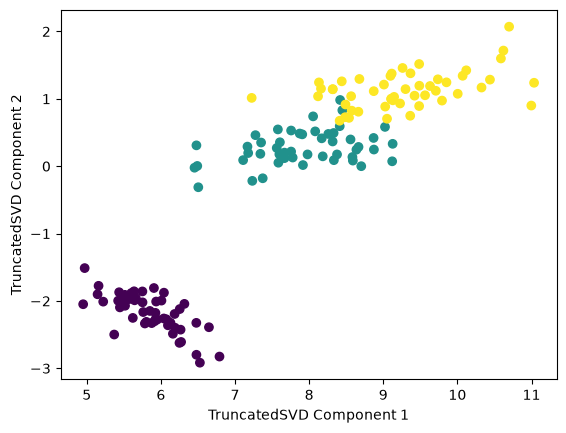

In [ ]:
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
%matplotlib inline

iris=load_iris()
iris_ftrs= iris.data
#2개의 주요 컴포넌트로 TruncatedSVD 변환 
tsvd= TruncatedSVD(n_components=2)
tsvd.fit(iris_ftrs)
iris_tsvd= tsvd.transform(iris_ftrs)

#산점도 2차원으로 TruncatedSVD 변환된 데이터 표현. 품종은 색깔로 구분 
plt.scatter(x=iris_tsvd[:, 0], y=iris_tsvd[:, 1], c=iris.target)
plt.xlabel('TruncatedSVD Component 1')
plt.ylabel('TruncatedSVD Component 2')

#품종별로 구분 가능. -> 역시 뛰어난 성능. 

Text(0.5, 1.0, 'PCA Transformed')

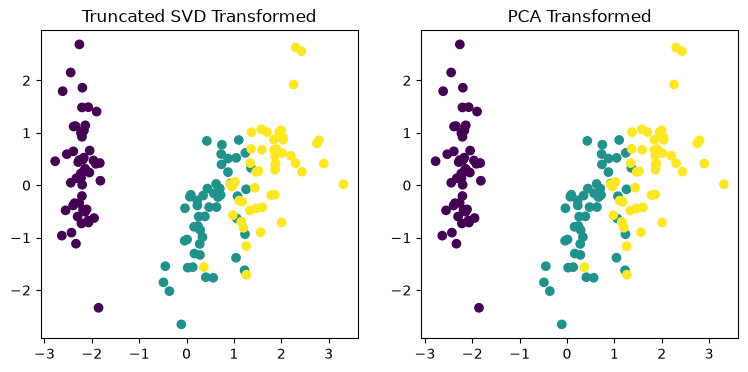

In [39]:
from sklearn.preprocessing import StandardScaler

#붓꽃 데이터를 StandardScaler로 변환 
scaler= StandardScaler()
iris_scaled= scaler.fit_transform(iris_ftrs)

#스케일링된 데이터를 기반으로 TruncatedSVD 변환 수행 
tsvd= TruncatedSVD(n_components=2)
tsvd.fit(iris_scaled)
iris_tsvd= tsvd.transform(iris_scaled)

#스케일링된 데이터를 기반으로 PCA 변환 수행 
pca= PCA(n_components=2)
pca.fit(iris_scaled)
iris_pca= pca.transform(iris_scaled)

#TruncatedSVD 변환 데이터를 왼쪽, PCA 변환 데이터를 오른쪽에 표현 
fig, (ax1, ax2)= plt.subplots(figsize=(9,4), ncols=2)
ax1.scatter(x=iris_tsvd[:, 0], y=iris_tsvd[:, 1], c=iris.target)
ax2.scatter(x=iris_pca[:, 0], y=iris_pca[:, 1], c=iris.target)
ax1.set_title('Truncated SVD Transformed')
ax2.set_title('PCA Transformed')


In [ ]:
print((iris_pca- iris_tsvd).mean())
print((pca.components_- tsvd.components_).mean())
#모두 0에 가까우므로 2개의 변환이 서로 동일함. 

2.3501571059606855e-15
1.491862189340054e-16


# 6.5 NMF 

c:\Users\0510n\anaconda3\Lib\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


Text(0, 0.5, 'NMF Component 2')

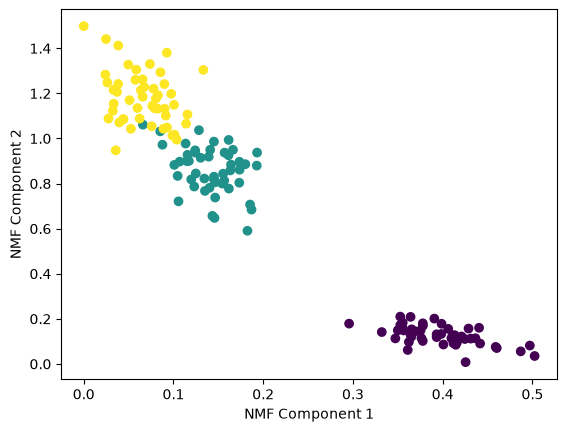

In [41]:
from sklearn.decomposition import NMF
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
%matplotlib inline

iris= load_iris()
iris_ftrs= iris.data
nmf= NMF(n_components=2)
nmf.fit(iris_ftrs)
iris_nmf= nmf.transform(iris_ftrs)
plt.scatter(x= iris_nmf[:, 0], y=iris_nmf[:, 1], c=iris.target)
plt.xlabel('NMF Component 1')
plt.ylabel('NMF Component 2')